# 02 - Meri trades ka review (think aloud)

**Kaam:** tumhari asli trades ko chart pe dekhna, aur tum batao ki wahan kya dekha tha. Isse tumhare setups ki definition niklegi.

**Kaise use karna hai:**
1. Upar se saare cells chalao (**Run → Run All Cells**)
2. Har trade ke 2 charts aayenge: **H1** (bada picture) aur **M5** (entry ke aas paas)
3. Har trade ke neeche wale notes cell mein likho: kya dekha, kyun entry li. Short mein, apni language mein

**Chart mein kya kya hai:**
- Green triangle ▲ = BUY entry, Red triangle ▼ = SELL entry, Black X = exit
- Background colours = sessions: **blue** = Asian, **green** = London, **orange** = New York (overlap mein green + orange dono)
- **Purple dashed** = us din ke Asian session ka high/low
- **Grey dotted** = Previous Day High / Low (PDH / PDL)
- Time **IST** mein hai

Note: abhi sirf M5 data hai. 8-minute ke scalps ke liye M1 better hoga, wo baad mein download karenge.

## 1. Setup: data load

In [1]:
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
TRADES_FILE = ROOT / "data" / "manual_trades" / "profitable_trades.csv"

m5 = pd.read_parquet(DATA / "XAUUSD_M5.parquet")
h1 = pd.read_parquet(DATA / "XAUUSD_H1.parquet")
d1 = pd.read_parquet(DATA / "XAUUSD_D1.parquet")
orders = pd.read_csv(TRADES_FILE, parse_dates=["Date"])
print(f"Orders: {len(orders)}  |  M5 candles: {len(m5):,}")

Orders: 325  |  M5 candles: 760,923


## 2. Orders → poore trades (FIFO)

File mein sirf **orders** hain (buy aur sell alag alag). Ye nahi likha ki kaunsa sell kis buy ko band karta hai. **FIFO** (First In, First Out) = jo position pehle khuli, wo pehle band hoti hai. Isse har entry ko uske exit se jodte hain.

`points` = price kitna tumhare favour mein gaya (gold mein $1 move = 1 point).

In [2]:
gold = orders[orders["Pair"] == "XAU/USD"].sort_values("Date")

open_lots = deque()   # (signed qty, price, time):  +qty = long, -qty = short
trades = []
for o in gold.itertuples(index=False):
    qty = o[5]                        # "Lot Size" column
    side = 1 if o.Side == "buy" else -1
    # Ulti side ka order aaya -> purani position band karo (FIFO)
    while qty > 1e-9 and open_lots and np.sign(open_lots[0][0]) != side:
        lot_qty, entry_price, entry_time = open_lots[0]
        matched = min(abs(lot_qty), qty)
        direction = "BUY" if lot_qty > 0 else "SELL"
        points = (o.Price - entry_price) if direction == "BUY" else (entry_price - o.Price)
        trades.append(dict(entry_time=entry_time, exit_time=o.Date, direction=direction,
                           lot=matched, entry=entry_price, exit=o.Price,
                           points=points, exit_type=o.Type))
        if abs(lot_qty) - matched < 1e-9:
            open_lots.popleft()
        else:
            open_lots[0] = (lot_qty - np.sign(lot_qty) * matched, entry_price, entry_time)
        qty -= matched
    if qty > 1e-9:                    # bacha hua qty = nayi position
        open_lots.append((side * qty, o.Price, o.Date))

trades = pd.DataFrame(trades)
trades["lot"] = trades["lot"].round(2)   # float ka kachra hatao (0.30000000004 -> 0.3)
trades["hold_min"] = (trades["exit_time"] - trades["entry_time"]).dt.total_seconds() / 60
trades["entry_ist"] = trades["entry_time"].dt.tz_convert("Asia/Kolkata")
print(f"Poore trades: {len(trades)}")
trades.tail()

Poore trades: 272


,entry_time,exit_time,direction,lot,entry,exit,points,exit_type,hold_min,entry_ist
267,2026-09-21 13:41:21.735000+00:00,2026-09-21 13:55:36.830000+00:00,SELL,0.3,4355.27,4349.29,5.98,market,14.251583,2026-09-21 19:11:21.735000+05:30
268,2026-09-21 13:55:36.830000+00:00,2026-09-22 06:17:05.969000+00:00,BUY,0.7,4349.29,4319.07,-30.22,market,981.485650,2026-09-21 19:25:36.830000+05:30
269,2026-09-22 06:17:05.969000+00:00,2026-09-22 06:23:30.380000+00:00,SELL,0.3,4319.07,4319.03,0.04,stop_loss,6.406850,2026-09-22 11:47:05.969000+05:30
270,2026-09-22 06:23:30.380000+00:00,2026-09-22 07:44:31.319000+00:00,BUY,0.7,4319.03,4309.52,-9.51,market,81.015650,2026-09-22 11:53:30.380000+05:30
271,2026-09-22 07:44:31.319000+00:00,2026-09-22 07:51:40.396000+00:00,SELL,0.3,4309.52,4304.52,5.00,take_profit,7.151283,2026-09-22 13:14:31.319000+05:30


## 3. Review ke liye trades chuno

Default: **aakhri 5 winning scalps** (1 ghante se kam hold). Doosre trades dekhne hain toh `REVIEW` wali line badlo. Jaise:
- `trades[(trades.hold_min <= 60) & (trades.points > 0)].tail(10)` → aakhri 10 winning scalps
- `trades[trades.points < 0].tail(5)` → aakhri 5 losing trades

In [3]:
REVIEW = trades[(trades["hold_min"] <= 60) & (trades["points"] > 0)].tail(5)
REVIEW[["entry_ist", "direction", "lot", "entry", "exit", "points", "hold_min", "exit_type"]].round(2)

C:\Users\Prxj\AppData\Local\Temp\ipykernel_4200\2197521353.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  REVIEW[["entry_ist", "direction", "lot", "entry", "exit", "points", "hold_min", "exit_type"]].round(2)


,entry_ist,direction,lot,entry,exit,points,hold_min,exit_type
256,2026-09-14 03:43:36.158000+05:30,SELL,0.1,4333.15,4331.89,1.26,12.52,stop_loss
261,2026-09-17 17:32:26.986000+05:30,BUY,0.3,4348.91,4352.37,3.46,7.92,stop_loss
267,2026-09-21 19:11:21.735000+05:30,SELL,0.3,4355.27,4349.29,5.98,14.25,market
269,2026-09-22 11:47:05.969000+05:30,SELL,0.3,4319.07,4319.03,0.04,6.41,stop_loss
271,2026-09-22 13:14:31.319000+05:30,SELL,0.3,4309.52,4304.52,5.00,7.15,take_profit


## 4. Chart banane wale functions

- `candles()` = candlestick chart. matplotlib mein ready-made candlestick nahi hota, isliye har candle = ek line (wick) + ek rectangle (body)
- Candles ko 0, 1, 2... position pe rakhte hain (time pe nahi), taaki weekend ya daily break ke gaps chart pe khaali jagah na banayein
- `session_of()` = har candle ka session (notebook 01 wala logic)

In [4]:
IST = "Asia/Kolkata"

def session_of(index):
    tokyo = np.asarray(index.tz_convert("Asia/Tokyo").hour)
    london = np.asarray(index.tz_convert("Europe/London").hour)
    ny = np.asarray(index.tz_convert("America/New_York").hour)
    in_asia = (tokyo >= 9) & (tokyo < 18)
    in_london = (london >= 8) & (london < 17)
    in_ny = (ny >= 8) & (ny < 17)
    return np.select([in_london & in_ny, in_london, in_ny, in_asia],
                     ["London+NY", "London", "New York", "Asian"], default="Off")

# Overlap mein do colours: upar aadha green (London), neeche aadha orange (NY)
SESSION_COLOURS = {"Asian": ["#cfe3ff"], "London": ["#d5f5d5"], "New York": ["#ffe3c2"],
                   "London+NY": ["#ffe3c2", "#d5f5d5"]}

def trade_date_of(ts):
    """Kis trading din ka hai (NY 5 PM wala din), build_timeframes jaisa hi."""
    return (ts.tz_convert("America/New_York") + pd.Timedelta(hours=7)).normalize().tz_localize(None)

def candles(ax, df, shade_sessions=False):
    x = np.arange(len(df))
    up = (df["close"] >= df["open"]).to_numpy()
    colours = np.where(up, "#26a69a", "#ef5350")
    ax.vlines(x, df["low"], df["high"], color=colours, linewidth=0.8, zorder=2)
    body_low = np.minimum(df["open"], df["close"])
    body_h = np.maximum((df["close"] - df["open"]).abs(), 0.05)
    ax.bar(x, body_h, bottom=body_low, color=colours, width=0.7, zorder=3)

    if shade_sessions:
        for i, s in enumerate(session_of(df.index)):
            cols = SESSION_COLOURS.get(s, [])
            for j, c in enumerate(cols):
                ax.axvspan(i - 0.5, i + 0.5, ymin=j / len(cols), ymax=(j + 1) / len(cols),
                           color=c, alpha=0.7, lw=0, zorder=0)

    # X-axis pe IST time
    step = max(len(df) // 10, 1)
    ax.set_xticks(x[::step])
    ax.set_xticklabels(df.index[::step].tz_convert(IST).strftime("%d %b %H:%M"),
                       rotation=30, ha="right", fontsize=8)
    ax.grid(alpha=0.2)

def pos_of(df, ts):
    """Kisi time ke liye chart pe candle ki position (x)."""
    return df.index.searchsorted(ts, side="right") - 1

## 5. Trade ka chart

Har trade ke liye:
- **Left, H1:** entry se pehle ke 5 din. Bada trend, structure aur zones yahan dekho. **Sirf wo H1 candles hain jo entry ke waqt band ho chuki thi** (lookahead nahi)
- **Right, M5:** entry se ~10 ghante pehle se exit ke 2 ghante baad tak, sessions ke colour ke saath

In [5]:
def plot_trade(t):
    entry_t, exit_t = t.entry_time, t.exit_time
    td = trade_date_of(entry_t)

    # PDH / PDL: pichle trading din ka high/low
    prev_day = d1[d1["trade_date"] < td].iloc[-1]
    pdh, pdl = prev_day["high"], prev_day["low"]

    # Asian range: isi trading din ke Asian session ka high/low (entry se pehle tak)
    day_m5 = m5[(m5.index <= entry_t) & (m5.index >= entry_t - pd.Timedelta(hours=24))]
    same_day = np.array([trade_date_of(ts) == td for ts in day_m5.index], dtype=bool)
    day_m5 = day_m5[same_day]
    asian = day_m5[session_of(day_m5.index) == "Asian"]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 1.4]})
    marker = "^" if t.direction == "BUY" else "v"
    mcol = "green" if t.direction == "BUY" else "red"

    # ---- H1: sirf closed candles (close_time <= entry)
    h = h1[(h1["close_time"] <= entry_t) & (h1.index >= entry_t - pd.Timedelta(days=5))]
    candles(ax1, h)
    ax1.axhline(pdh, color="grey", ls=":", lw=1)
    ax1.axhline(pdl, color="grey", ls=":", lw=1)
    ax1.scatter(len(h) - 0.5, t.entry, marker=marker, color=mcol, s=150, zorder=5)
    ax1.set_title("H1 (last 5 days, entry se pehle tak)")

    # ---- M5 window
    w = m5[(m5.index >= entry_t - pd.Timedelta(hours=10)) & (m5.index <= exit_t + pd.Timedelta(hours=2))]
    candles(ax2, w, shade_sessions=True)
    ax2.set_ylim(w["low"].min() - 2, w["high"].max() + 2)
    if len(asian):
        ax2.axhline(asian["high"].max(), color="purple", ls="--", lw=1, label="Asian high/low")
        ax2.axhline(asian["low"].min(), color="purple", ls="--", lw=1)
    for lvl, name in [(pdh, "PDH"), (pdl, "PDL")]:
        if w["low"].min() - 2 < lvl < w["high"].max() + 2:
            ax2.axhline(lvl, color="grey", ls=":", lw=1.2)
            ax2.text(0, lvl, f" {name}", va="bottom", fontsize=8, color="grey")
    ax2.scatter(pos_of(w, entry_t), t.entry, marker=marker, color=mcol, s=180, zorder=5,
                label=f"{t.direction} entry")
    ax2.scatter(pos_of(w, exit_t), t.exit, marker="x", color="black", s=150, zorder=5,
                label=f"exit ({t.exit_type})")
    ax2.legend(loc="upper left", fontsize=8)
    ax2.set_title("M5 (blue=Asian, green=London, orange=NY)")

    ist = entry_t.tz_convert(IST)
    fig.suptitle(f"{t.direction} | {ist:%d %b %Y %H:%M} IST | entry {t.entry:.2f} → exit {t.exit:.2f} | "
                 f"{t.points:+.2f} pts | {t.hold_min:.0f} min | lot {t.lot}", fontsize=12)
    plt.tight_layout()
    plt.show()

## Trade 1

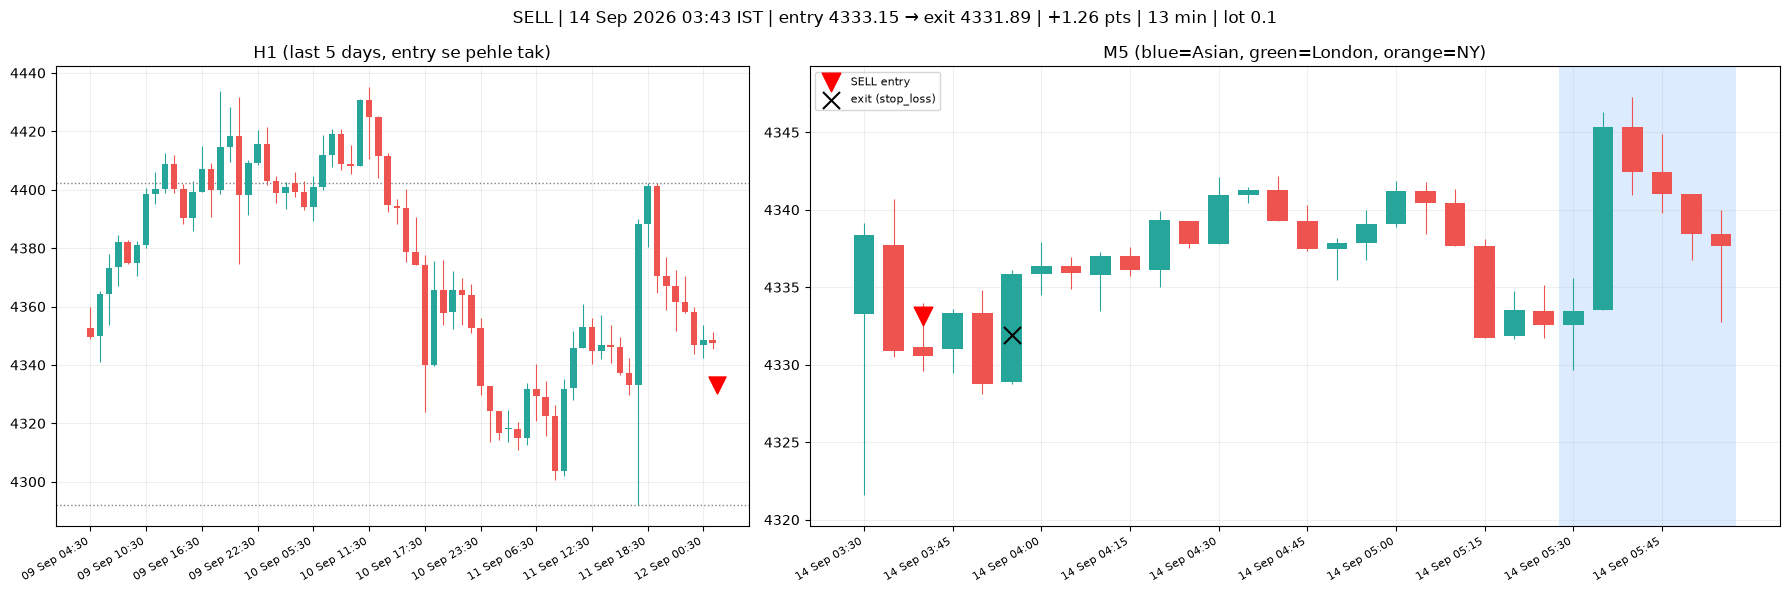

In [6]:
plot_trade(REVIEW.iloc[0])

**Trade 1: tumhare notes** (is cell pe double-click karke likho, phir `Shift + Enter`)
- HTF (H1/H4/D1) pe kya dekha:
- Kaunsa zone / level tha:
- Sweep / trap hua tha kya:
- Entry kyun li (kya confirmation dekha):
- SL / TP kaise decide kiya:

## Trade 2

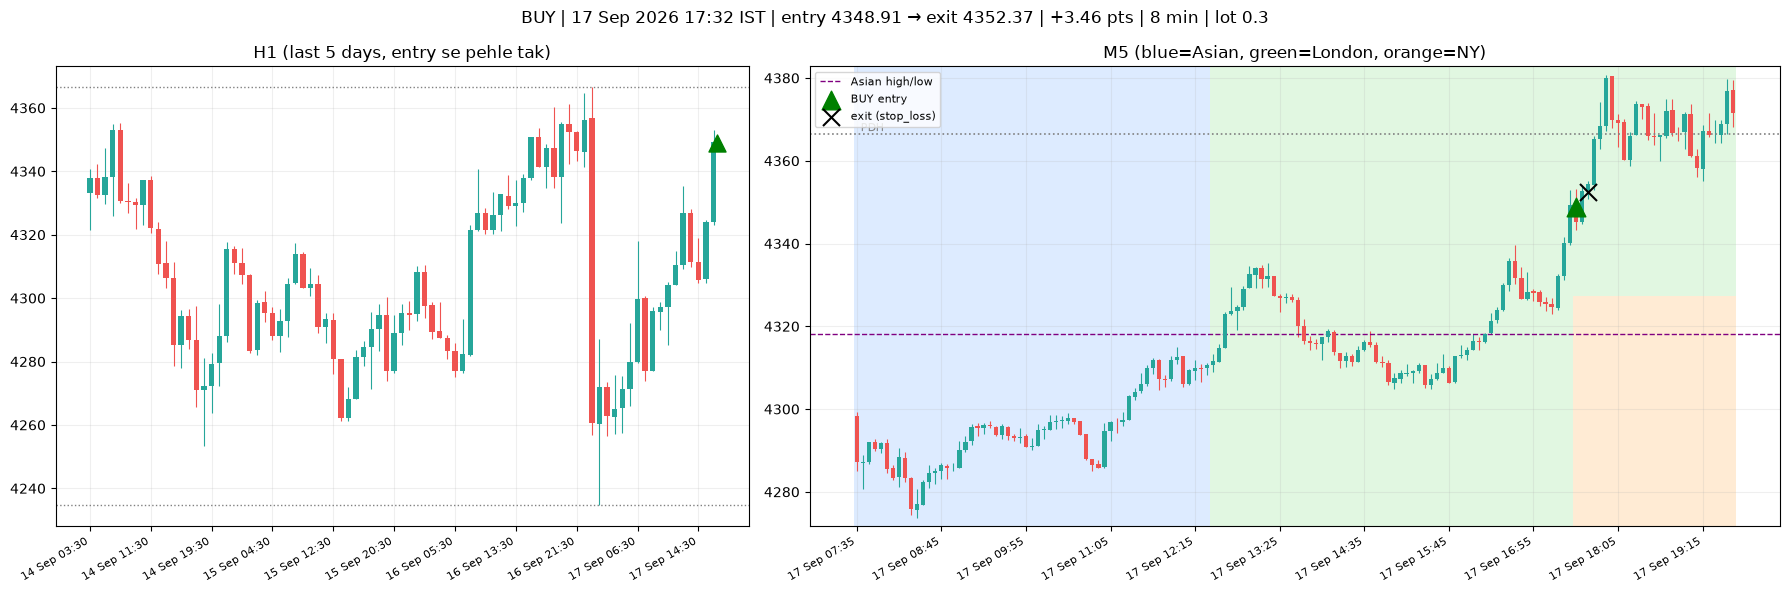

In [7]:
plot_trade(REVIEW.iloc[1])

**Trade 2: tumhare notes** (is cell pe double-click karke likho, phir `Shift + Enter`)
- HTF (H1/H4/D1) pe kya dekha:
- Kaunsa zone / level tha:
- Sweep / trap hua tha kya:
- Entry kyun li (kya confirmation dekha):
- SL / TP kaise decide kiya:

## Trade 3

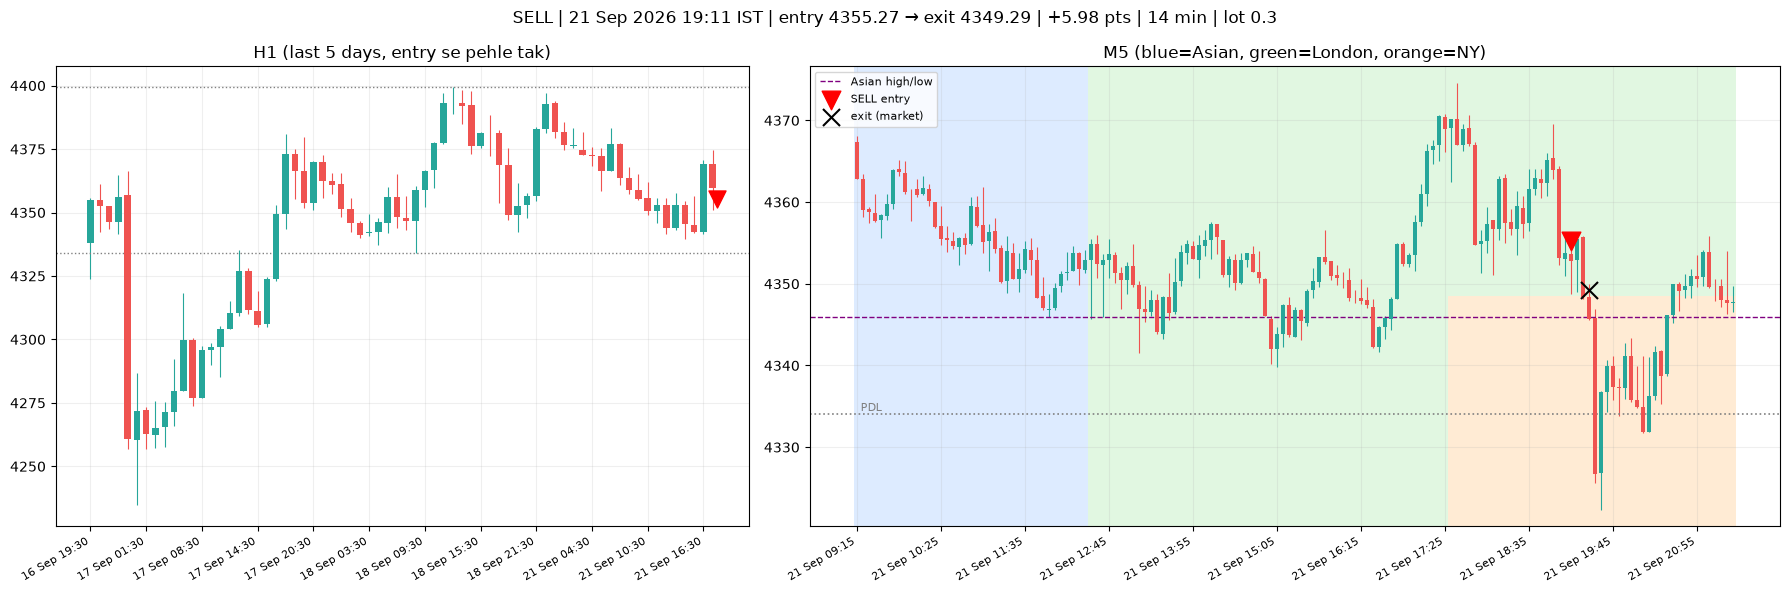

In [8]:
plot_trade(REVIEW.iloc[2])

**Trade 3: tumhare notes** (is cell pe double-click karke likho, phir `Shift + Enter`)
- HTF (H1/H4/D1) pe kya dekha:
- Kaunsa zone / level tha:
- Sweep / trap hua tha kya:
- Entry kyun li (kya confirmation dekha):
- SL / TP kaise decide kiya:

## Trade 4

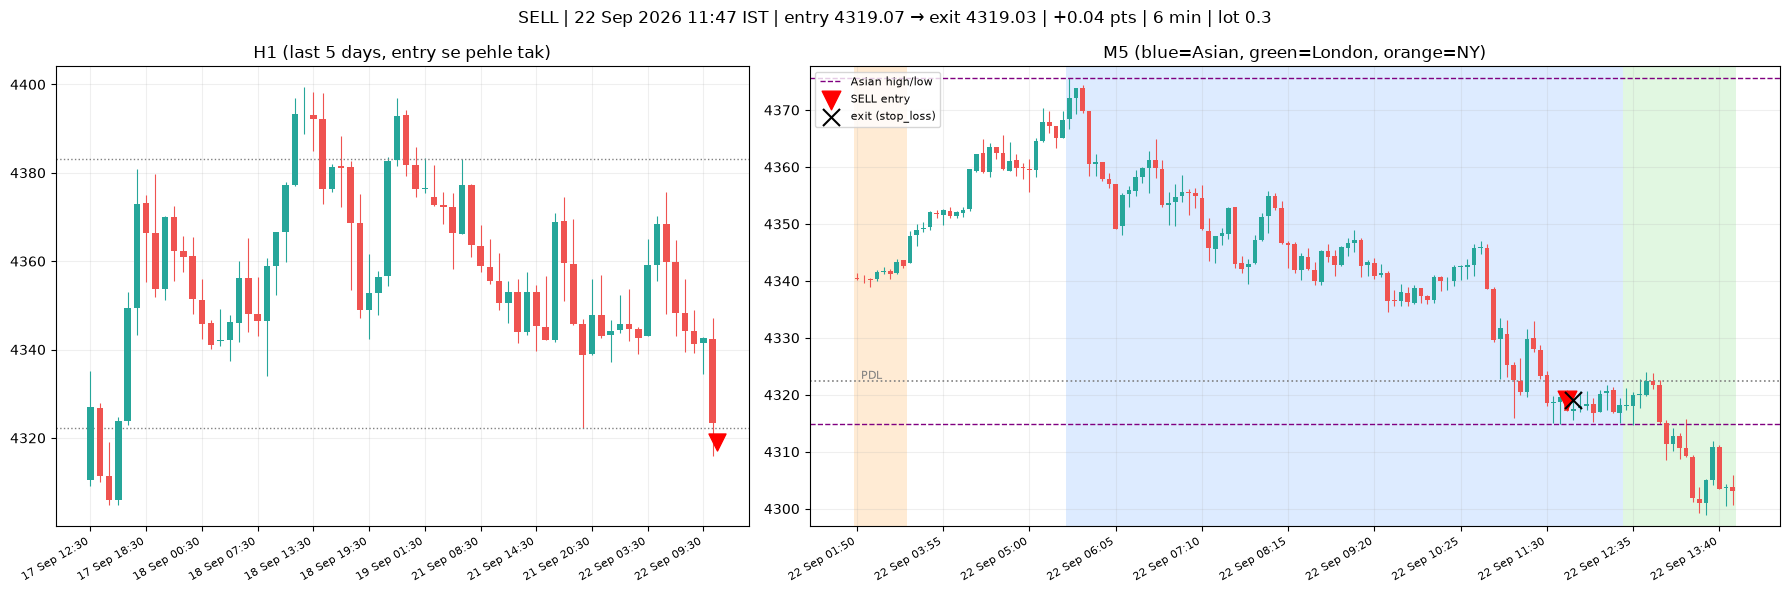

In [9]:
plot_trade(REVIEW.iloc[3])

**Trade 4: tumhare notes** (is cell pe double-click karke likho, phir `Shift + Enter`)
- HTF (H1/H4/D1) pe kya dekha:
- Kaunsa zone / level tha:
- Sweep / trap hua tha kya:
- Entry kyun li (kya confirmation dekha):
- SL / TP kaise decide kiya:

## Trade 5

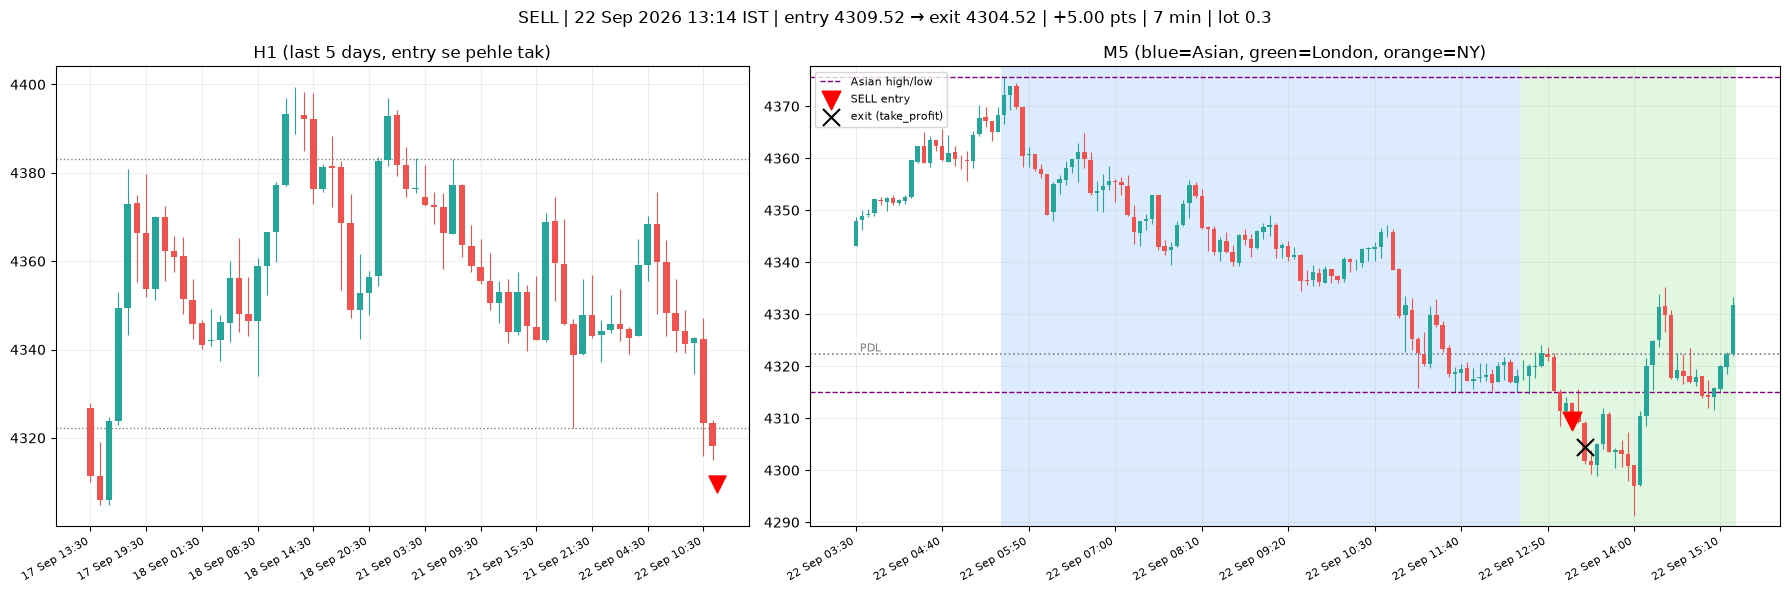

In [10]:
plot_trade(REVIEW.iloc[4])

**Trade 5: tumhare notes** (is cell pe double-click karke likho, phir `Shift + Enter`)
- HTF (H1/H4/D1) pe kya dekha:
- Kaunsa zone / level tha:
- Sweep / trap hua tha kya:
- Entry kyun li (kya confirmation dekha):
- SL / TP kaise decide kiya: